# 11-1. CRPS 순위 비교 (crps7 vs crps_ensemble, 16개 조합)

4개 모델 x 스케일(원, 로그) x 구간(리샘플링, 자체) = 16개 조합의 CRPS를 두 방식으로 비교한다. `11-2`~`11-6`이 이 결과를 쓴다.
- `crps7`: 분위수 7개(τ = 0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9)의 pinball loss 평균 x 2
- `crps_ensemble`: 구간별 앙상블(리샘플링 500개, 자체는 정규 분위수 500개, 로그는 `exp`)을 입력

원 스케일에서 `var_std`로 나누고 88개(22 origin x h=1~4)를 평균한다.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from arch.univariate import ARX, ZeroMean, GARCH
from scipy import stats

H, MIN_TRAIN, INITIAL_CALIB, ALPHA = 4, 20, 15, 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
D, N_RESAMPLE, P_MAX, SCALE = 1, 500, 3, 100.0

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
data = raw[["quarter", "X3_l1"]].dropna().reset_index(drop=True)
quarters, vals = data["quarter"].values, data["X3_l1"].values.astype(float)
LOG = SCALE * np.log(vals)
var_std = vals.std()
origins = list(range(MIN_TRAIN, len(vals) - H + 1))
scored_origins = origins[INITIAL_CALIB:]
FIRST = scored_origins[0]
LEVELS = np.array([0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9])


def label(o):
    return f"origin {o} (훈련 {quarters[0]}~{quarters[o - 1]}, 예측 {quarters[o]}~{quarters[o + H - 1]})"


def pinball(q, y, tau):
    return np.where(y >= q, (y - q) * tau, (q - y) * (1 - tau))


def crps7(q7, y):
    return 2 * np.mean([pinball(q7[k], y, LEVELS[k]) for k in range(7)]) / var_std


def to_orig(x):
    return np.exp(np.asarray(x) / SCALE)


def difference(values, d):
    x = np.asarray(values, dtype=float)
    hist = []
    for _ in range(d):
        hist.append(x.copy())
        x = np.diff(x)
    return x, hist


def undiff_mean(diff_fc, hist, d):
    fc = np.asarray(diff_fc, dtype=float)
    for i in reversed(range(d)):
        fc = hist[i][-1] + np.cumsum(fc)
    return fc


def level_sigma(ar_coefs, d, innov_var):
    p = len(ar_coefs)
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(ar_coefs[k] * psi[j - 1 - k] for k in range(min(p, j)))
    for _ in range(d):
        psi = np.cumsum(psi)
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def select_p(train):
    # AR단독 auto_arima(정확우도, AICc): d=1 고정, MA 없음, 절편 없음 -> GARCH의 AR 차수로 사용
    m = pm.auto_arima(train, d=D, seasonal=False, start_q=0, max_q=0, max_p=P_MAX, information_criterion="aicc",
                      with_intercept=False, suppress_warnings=True, error_action="ignore")
    return m.order[0], m


def ar_fallback(m):
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z)


def garch_forecast(train, p):
    diff_train, hist = difference(train, D)
    am = ZeroMean(diff_train, rescale=False) if p == 0 else ARX(diff_train, lags=p, constant=False, rescale=False)
    am.volatility = GARCH(p=1, q=1)
    res = am.fit(disp="off")
    f = res.forecast(horizon=H, reindex=False)
    ar = [res.params[f"y[{k}]"] for k in range(1, p + 1)]
    fc = undiff_mean(f.mean.values[-1], hist, D)
    sig = level_sigma(ar, D, f.residual_variance.values[-1])
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


def model_forecast(series):
    # AR 차수 p는 AR단독 auto_arima가 선택, 적합 실패 시 AR단독 예측으로 대체(대체 횟수는 기록)
    p, m = select_p(series)
    try:
        fc, sig = garch_forecast(series, p)
        return fc, sig, "GARCH", p
    except Exception:
        fc, sig = ar_fallback(m)
        return fc, sig, "AR대체", p


def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2 ** 32))

from scipy.optimize import minimize
XI_MEAN, XI_VAR, MAX_PHI = -1.2704, np.pi ** 2 / 2, 0.97
def is_ar_stable(ar_coefs):
    p = len(ar_coefs)
    if p == 0:
        return True
    companion = np.zeros((p, p))
    companion[0, :] = ar_coefs
    if p > 1:
        companion[1:, :-1] = np.eye(p - 1)
    return np.max(np.abs(np.linalg.eigvals(companion))) < 0.999


def level_sigma(ar_coefs, d, innov_var):
    # ARIMA(p,d,0)의 h단계 수준 예측오차 표준편차 (innov_var[i] = (i+1)단계 오차분산)
    p = len(ar_coefs)
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(ar_coefs[k] * psi[j - 1 - k] for k in range(min(p, j)))
    for _ in range(d):
        psi = np.cumsum(psi)
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def sv_residuals(y, ar):
    p = len(ar)
    return np.array([y[t] - sum(ar[i] * y[t - 1 - i] for i in range(p)) for t in range(p, len(y))])


def joint_sv_negloglik(params, y, p):
    ar, phi, s2 = params[:p], MAX_PHI * np.tanh(params[p]), np.exp(params[p + 1]) ** 2
    if not is_ar_stable(ar):
        return 1e10
    z = np.log(sv_residuals(y, ar) ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, s2)


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def sv_residuals(y, ar):
    p = len(ar)
    return np.array([y[t] - sum(ar[i] * y[t - 1 - i] for i in range(p)) for t in range(p, len(y))])


def joint_sv_negloglik(params, y, p):
    ar, phi, s2 = params[:p], MAX_PHI * np.tanh(params[p]), np.exp(params[p + 1]) ** 2
    if not is_ar_stable(ar):
        return 1e10
    z = np.log(sv_residuals(y, ar) ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, s2)


def sv_forecast(train, p):
    y, hist = difference(train, D)
    res = minimize(joint_sv_negloglik, [0.0] * p + [1.5, np.log(0.3)], args=(y, p), method="Nelder-Mead", options={"maxiter": 3000})
    if not is_ar_stable(res.x[:p]) or res.fun >= 1e9:
        raise ValueError("SV fit failed")
    ar, phi, s2 = res.x[:p], MAX_PHI * np.tanh(res.x[p]), np.exp(res.x[p + 1]) ** 2
    z = np.log(sv_residuals(y, ar) ** 2 + 1e-8)
    zm = z.mean()
    P, h = s2 / (1 - phi ** 2), 0.0
    for x in z - zm:
        K = P / (P + XI_VAR)
        hf, Pf = h + K * (x - h), P * (1 - K)
        h, P = phi * hf, phi ** 2 * Pf + s2
    past = list(y[-p:]) if p else []
    mean_diff = []
    for _ in range(H):
        pred = sum(ar[i] * past[-1 - i] for i in range(p))
        mean_diff.append(pred)
        past.append(pred)
    v = [np.exp(zm - XI_MEAN + phi ** k * hf + (phi ** (2 * k) * Pf + s2 * sum(phi ** (2 * j) for j in range(k))) / 2) for k in range(1, H + 1)]
    fc, sig = undiff_mean(mean_diff, hist, D), level_sigma(ar, D, v)
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig





def fc_garch(series):
    fc, sig, src, p = model_forecast(series)          # GARCH (실패 시 AR단독으로 대체)
    return fc, sig


def fc_sv(series):
    p, m = select_p(series)
    try:
        fc, sig = sv_forecast(series, p)
    except Exception:
        fc, sig = ar_fallback(m)
    return fc, sig


def fc_auto(series):
    m = pm.auto_arima(series, d=D, seasonal=False, information_criterion="aicc", suppress_warnings=True, error_action="ignore")
    fc = np.asarray(m.predict(n_periods=H))
    _, c90 = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return fc, (c90[:, 1] - c90[:, 0]) / (2 * Z)


def fc_ar(series):
    p, m = select_p(series)
    return ar_fallback(m)


# 모델: (예측 함수, 오차 표준화 여부, 원 시드, 로그 시드)
MODELS = {
    "auto_arima": (fc_auto, False, "X3_l1_9-3_resample_vs_self", "X3_l1_9-4_log_resample_vs_self"),
    "AR단독": (fc_ar, False, "X3_l1_9-10_ar_orig", "X3_l1_9-10_ar_log"),
    "GARCH": (fc_garch, True, "X3_l1_9-6_garch_orig", "X3_l1_9-7_garch_log"),
    "SV": (fc_sv, True, "X3_l1_9-8_sv_orig", "X3_l1_9-9_sv_log"),
}

import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
N_ENS = 500
U = stats.norm.ppf((np.arange(N_ENS) + 0.5) / N_ENS)      # 표준정규 분위수 500개 (난수 없음)
print(f"채점 origin {len(scored_origins)}개, var_std = {var_std:.3f}")

채점 origin 22개, var_std = 282.627


## 1. 계산

리샘플링 오차 표본은 실제값이 확정된 과거 오차(`o' + h <= o`)만 쓴다. 캘리브레이션 origin(20~34)의 구간도 따로 저장한다(`11-6`용, 자체는 전부, 리샘플링은 오차 표본 8개 이상).

In [2]:
CACHE = "../cache/cache_107_rank_compare_df.pkl"
CACHE_CAL = "../cache/cache_107_calib_df.pkl"      # 캘리브레이션 origin(20~34)의 구간 (11-6에서 k 추정에 사용)


def run(model, logmode):
    fn, std, seed_o, seed_l = MODELS[model]
    rng = rng_for(seed_l if logmode else seed_o)
    tf = to_orig if logmode else (lambda x: x)
    rng_c = rng_for((seed_l if logmode else seed_o) + "_calib")          # 캘리브레이션 구간용 별도 난수(채점 결과에 영향 없음)
    errs = {h: [] for h in range(1, H + 1)}      # h별 (오차를 낸 origin, 오차)
    rows, cal = [], []
    for oi, o in enumerate(origins):
        train, actual = (LOG[:o] if logmode else vals[:o]), vals[o:o + H]
        fc, sig = fn(train)
        if oi < INITIAL_CALIB:
            for h in range(1, H + 1):
                a, s_h = actual[h - 1], max(sig[h - 1], 1e-6)
                pool = np.array([e for o2, e in errs[h] if o2 + h <= o])
                base = {"모델": model, "스케일": "로그" if logmode else "원", "origin": o, "h": h, "fc": float(tf(fc[h - 1])), "actual": a, "pool_n": len(pool)}
                lo_n, hi_n = tf(fc[h - 1] - Z * s_h), tf(fc[h - 1] + Z * s_h)
                cal.append({**base, "구간": "자체", "lo": lo_n, "hi": hi_n})
                if len(pool) >= 8:                                       # 오차 표본이 너무 작은 구간은 만들지 않음
                    samples = fc[h - 1] + (s_h if std else 1.0) * rng_c.choice(pool - np.median(pool), size=N_RESAMPLE, replace=True)
                    lo_r, hi_r = tf(np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2]))
                    cal.append({**base, "구간": "리샘플링", "lo": lo_r, "hi": hi_r})
        if oi >= INITIAL_CALIB:
            for h in range(1, H + 1):
                a = actual[h - 1]
                s_h = max(sig[h - 1], 1e-6)
                scale = s_h if std else 1.0
                pool = np.array([e for o2, e in errs[h] if o2 + h <= o])      # 정답이 이미 관측된 오차만
                samples = fc[h - 1] + scale * rng.choice(pool - np.median(pool), size=N_RESAMPLE, replace=True)
                q_res = tf(np.quantile(samples, LEVELS))
                lo_r, hi_r = tf(np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2]))
                lo_n, hi_n = tf(fc[h - 1] - Z * s_h), tf(fc[h - 1] + Z * s_h)
                med = float(tf(fc[h - 1]))
                extra = {"MSE": ((a - med) / var_std) ** 2, "fc": med, "actual": a, "pool_n": len(pool)}
                q_self = tf(fc[h - 1] + s_h * stats.norm.ppf(LEVELS))
                base = {"모델": model, "스케일": "로그" if logmode else "원", "origin": o, "h": h}
                rows.append({**base, **extra, "구간": "리샘플링", "적중": float(lo_r <= a <= hi_r) * 100, "lo": lo_r, "hi": hi_r, "crps7": crps7(q_res, a), "crps_ensemble": ps.crps_ensemble(a, tf(samples)) / var_std})
                rows.append({**base, **extra, "구간": "자체", "적중": float(lo_n <= a <= hi_n) * 100, "lo": lo_n, "hi": hi_n, "crps7": crps7(q_self, a), "crps_ensemble": ps.crps_ensemble(a, tf(fc[h - 1] + s_h * U)) / var_std})
        for h in range(1, H + 1):
            e = (np.log(actual[h - 1]) * SCALE if logmode else actual[h - 1]) - fc[h - 1]
            errs[h].append((o, e / max(sig[h - 1], 1e-6) if std else e))
    return pd.DataFrame(rows), pd.DataFrame(cal)


if os.path.exists(CACHE) and os.path.exists(CACHE_CAL):
    res, cal = pd.read_pickle(CACHE), pd.read_pickle(CACHE_CAL)
    print("캐시에서 로드:", len(res), "행, 캘리브레이션 구간", len(cal), "행")
else:
    out = [run(m, lg) for m in MODELS for lg in (False, True)]
    res, cal = pd.concat([o[0] for o in out], ignore_index=True), pd.concat([o[1] for o in out], ignore_index=True)
    res.to_pickle(CACHE)
    cal.to_pickle(CACHE_CAL)
    print("계산 완료:", len(res), "행, 캘리브레이션 구간", len(cal), "행")


캐시에서 로드: 1408 행, 캘리브레이션 구간 656 행


## 2. 평균 CRPS와 순위

낮을수록 1위. `순위 변화` = `crps7` 순위 - `crps_ensemble` 순위.

In [3]:
per = res.groupby(["모델", "스케일", "구간", "origin"])[["crps7", "crps_ensemble"]].mean()
tab = per.groupby(["모델", "스케일", "구간"]).mean()
for c in ["crps7", "crps_ensemble"]:
    tab[f"순위({c})"] = tab[c].rank().astype(int)
tab["순위 변화"] = tab["순위(crps7)"] - tab["순위(crps_ensemble)"]
tab["crps7 차이(%)"] = 100 * (tab["crps7"] / tab["crps_ensemble"] - 1)
tab = tab.sort_values("crps7")
display(tab.round(4))
from scipy.stats import spearmanr, kendalltau
print(f"crps7 순위 대 crps_ensemble 순위: Spearman {spearmanr(tab['crps7'], tab['crps_ensemble'])[0]:.4f}, Kendall {kendalltau(tab['crps7'], tab['crps_ensemble'])[0]:.4f}")
print("순위가 바뀐 조합 수:", int((tab["순위 변화"] != 0).sum()), "/ 16")

crps7  crps_ensemble  순위(crps7)  순위(crps_ensemble)  \
모델         스케일 구간                                                          
GARCH      원   자체    0.5892         0.5795          1                  2   
SV         원   자체    0.5894         0.5783          2                  1   
auto_arima 원   리샘플링  0.5951         0.5955          3                  5   
AR단독       원   리샘플링  0.6002         0.5986          4                  6   
               자체    0.6017         0.5931          5                  3   
SV         로그  자체    0.6164         0.5950          6                  4   
           원   리샘플링  0.6178         0.5987          7                  7   
auto_arima 원   자체    0.6210         0.6104          8                  8   
GARCH      원   리샘플링  0.6434         0.6248          9                  9   
AR단독       로그  자체    0.7033         0.6788         10                 10   
GARCH      로그  자체    0.7296         0.6854         11                 11   
AR단독       로그  리샘플링  0.7579         0.7250         12                 13   
SV         로그  리샘플링  0.7620         0.7146         13                 12   
auto_arima 로그  자체    0.7666         0.7493         14                 14   
               리샘플링  0.8340         0.8064         15                 15   
GARCH      로그  리샘플링  1.0296         0.9723         16                 16   

                     순위 변화  crps7 차이(%)  
모델         스케일 구간                        
GARCH      원   자체       -1       1.6897  
SV         원   자체        1       1.9229  
auto_arima 원   리샘플링     -2      -0.0650  
AR단독       원   리샘플링     -2       0.2615  
               자체        2       1.4619  
SV         로그  자체        2       3.5820  
           원   리샘플링      0       3.1906  
auto_arima 원   자체        0       1.7413  
GARCH      원   리샘플링      0       2.9749  
AR단독       로그  자체        0       3.6102  
GARCH      로그  자체        0       6.4475  
AR단독       로그  리샘플링     -1       4.5415  
SV         로그  리샘플링      1       6.6373  
auto_arima 로그  자체        0       2.2998  
               리샘플링      0       3.4238  
GARCH      로그  리샘플링      0       5.8930

crps7 순위 대 crps_ensemble 순위: Spearman 0.9706, Kendall 0.9000
순위가 바뀐 조합 수: 8 / 16


## 3. 순위가 바뀐 곳과 자체 vs 리샘플링의 우열

In [4]:
chg = tab[tab["순위 변화"] != 0][["crps7", "crps_ensemble", "순위(crps7)", "순위(crps_ensemble)", "순위 변화"]]
print("순위가 바뀐 조합:")
display(chg.round(4) if len(chg) else "없음")
rows = []
for (m, sc), g in tab.groupby(level=[0, 1]):
    r = {"모델": m, "스케일": sc}
    for c in ["crps7", "crps_ensemble"]:
        r[f"{c}: 낮은 쪽"] = "자체" if g.loc[(m, sc, "자체"), c] < g.loc[(m, sc, "리샘플링"), c] else "리샘플링"
    rows.append(r)
cmp_ = pd.DataFrame(rows).set_index(["모델", "스케일"])
display(cmp_)
print("모델 내 자체 대 리샘플링 우열이 달라진 칸 수:", int((cmp_["crps7: 낮은 쪽"] != cmp_["crps_ensemble: 낮은 쪽"]).sum()), "/ 8")

순위가 바뀐 조합:


crps7  crps_ensemble  순위(crps7)  순위(crps_ensemble)  \
모델         스케일 구간                                                          
GARCH      원   자체    0.5892         0.5795          1                  2   
SV         원   자체    0.5894         0.5783          2                  1   
auto_arima 원   리샘플링  0.5951         0.5955          3                  5   
AR단독       원   리샘플링  0.6002         0.5986          4                  6   
               자체    0.6017         0.5931          5                  3   
SV         로그  자체    0.6164         0.5950          6                  4   
AR단독       로그  리샘플링  0.7579         0.7250         12                 13   
SV         로그  리샘플링  0.7620         0.7146         13                 12   

                     순위 변화  
모델         스케일 구간           
GARCH      원   자체       -1  
SV         원   자체        1  
auto_arima 원   리샘플링     -2  
AR단독       원   리샘플링     -2  
               자체        2  
SV         로그  자체        2  
AR단독       로그  리샘플링     -1  
SV         로그  리샘플링      1

crps7: 낮은 쪽 crps_ensemble: 낮은 쪽
모델         스케일                                
AR단독       로그           자체                  자체
           원          리샘플링                  자체
GARCH      로그           자체                  자체
           원            자체                  자체
SV         로그           자체                  자체
           원            자체                  자체
auto_arima 로그           자체                  자체
           원          리샘플링                리샘플링

모델 내 자체 대 리샘플링 우열이 달라진 칸 수: 1 / 8


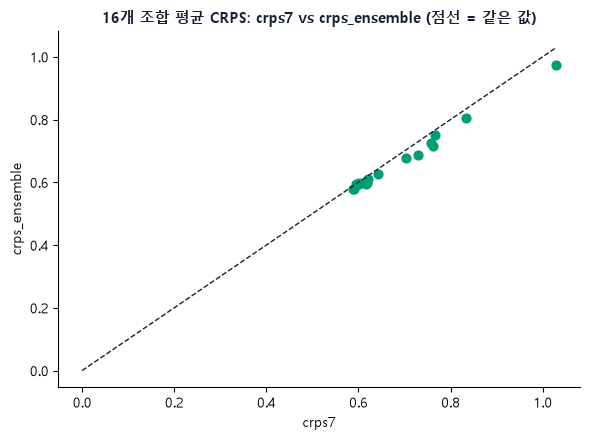

In [5]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(tab["crps7"], tab["crps_ensemble"], color="#009E73", s=40)
m_ = max(tab["crps7"].max(), tab["crps_ensemble"].max())
ax.plot([0, m_], [0, m_], color="#172033", linestyle="--", linewidth=1)
ax.set_xlabel("crps7")
ax.set_ylabel("crps_ensemble")
ax.set_title("16개 조합 평균 CRPS: crps7 vs crps_ensemble (점선 = 같은 값)", fontsize=10.5, fontweight="bold", color="#172033")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## 4. 결론

**`crps_ensemble`로 바꿔도 우열은 거의 같고, 원 스케일 상위권 순서만 바뀐다.**

- 순위: Spearman 0.9706, Kendall 0.9000, 바뀐 조합 8/16(대부분 CRPS 0.578~0.599의 상위 7개).
- 우열: 자체 vs 리샘플링 8칸 중 7칸 같음(AR단독 원만 다름).
- 값: `crps7`이 16개 중 15개에서 높다(-0.1~+6.6%).
- 한계: 22개 origin이 겹치고 유의성 검정은 하지 않았다.